In [1]:
%load_ext autoreload
%autoreload

%matplotlib ipympl

In [2]:
import numpy as np

import matplotlib.pyplot as plt

from scipy.integrate import odeint


import sys
sys.path.append('./celljobs/')
sys.path.append('./figjobs/')

# from figFcns_TeX import *


### Funkcie:

In [3]:
def fcn_LTIS(x, t, A, b, u):

    dotx = np.matmul(A, x) + np.matmul(b, u)

    return dotx

In [4]:
def fcn_simSch(t_start, T_s, finalIndex, sig_setpoint):


    #----------------------------------------------------
    # Alokacia casoveho vektora

    t_log = np.zeros([finalIndex, 1])
    t_log[0,:] = t_start

    #-----------------------------------------
    # Zaciatocne hodnoty signalov

    x_0 = np.zeros(b.shape[0])

    y_0 = np.dot(c.T, x_0.reshape(-1,1))

    e_0 = sig_setpoint[0,:] - y_0

    u_0 = par_P * e_0 + 0 + 0


    #-----------------------------------------
    # Alokacia poli pre zapis signalov (a zapisanie zaciatocnych podmienok)


    x_log = np.zeros([finalIndex, len(x_0)])
    x_log[0,:] = x_0

    y_log = np.zeros([finalIndex, 1])
    y_log[0,:] = y_0



    #-------------

    e_log = np.zeros([finalIndex, 1])
    e_log[0,:] = e_0

    int_e_log = np.zeros([finalIndex, 1])
    int_e_log[0,:] = 0

    der_e_log = np.zeros([finalIndex, 1])
    der_e_log[0,:] = 0

    u_log = np.zeros([finalIndex, 1])
    u_log[0,:] = u_0


    #----------------------------------------------------


    timespan = np.zeros(2)
    for idx in range(1, int(finalIndex)):

        timespan[0] = t_log[idx-1,:]
        timespan[1] = t_log[idx-1,:] + T_s

        t_log[idx,:] = timespan[-1]

        #-----------------------------------------
        # Riadeny system

        odeOut = odeint(fcn_LTIS,
                        x_log[idx-1,:],
                        timespan,
                        args=(A, b, u_log[idx-1,:])
                        )

        x_log[idx,:] = odeOut[-1,:]

        y_log[idx,:] = np.dot(c.T, x_log[idx,:].reshape(-1,1))


        #-----------------------------------------
        # Riadiaci system

        e_log[idx,:] = sig_setpoint[idx,:] - y_log[idx,:]

        der_e_log[idx,:] = (e_log[idx,:] - e_log[idx-1,:]) / T_s

        int_e_log[idx,:] = int_e_log[idx-1,:] + e_log[idx,:] * T_s

        u_log[idx,:] = par_P * e_log[idx,:] + par_I * int_e_log[idx,:]  + par_D * der_e_log[idx,:]






    return [t_log, x_log, y_log, u_log, e_log, der_e_log, int_e_log]



[-0.25+0.96824584j -0.25-0.96824584j]


C:\Users\MT\AppData\Local\Temp\ipykernel_25132\495973364.py:55: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  timespan[0] = t_log[idx-1,:]
C:\Users\MT\AppData\Local\Temp\ipykernel_25132\495973364.py:56: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  timespan[1] = t_log[idx-1,:] + T_s


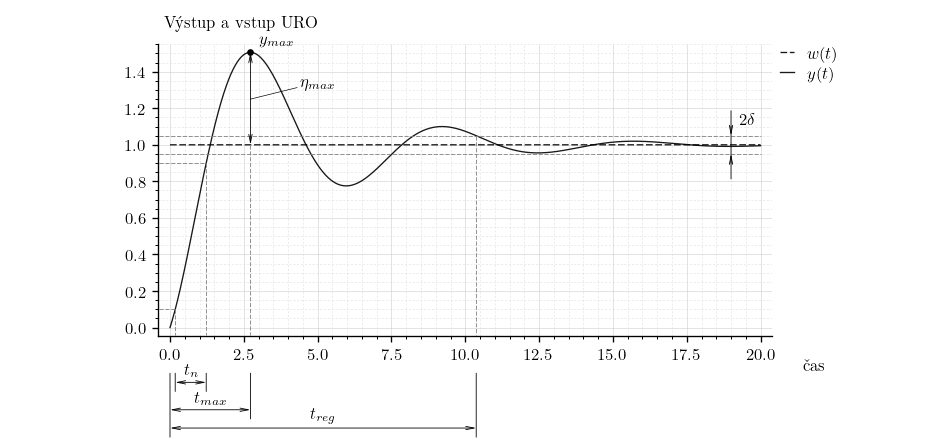

In [5]:
sim_t_start = 0
sim_t_final = 20
sim_T_s = 0.001
sim_finalIndex = int(((sim_t_final - sim_t_start)/sim_T_s) + 1)


sig_setpoint = np.ones([sim_finalIndex, 1])

#-----------------------------------------
# Parametre riadeneho systemu

b0 = 1
a0 = 0
# a1 = 1

A = np.array([[-a0]])
b = np.array([[1]])
c = np.array([[b0]])

#-----------------------------------------
# Parametre riadiaceho systemu

par_P = 0.5
par_I = 1
par_D = 0

print(np.roots([1, par_P, par_I]))

#-----------------------------------------

t_log, x_log, y_log, u_log, e_log, der_e_log, int_e_log, = fcn_simSch(sim_t_start, sim_T_s, sim_finalIndex, sig_setpoint)

#-----------------------------------------

figSaveDir = './fig/'
figName = 'MRS10_kvalitaPCHURO'
figNameNum = 0
exec(open('./figjobs/figsc_02.py', encoding='utf-8').read())


plt.show()